# Predicción de cancelaciones de reservas de hotel
**IA006 - Inteligencia Artificial - Proyecto segundo corte (implementación)**

Rafael Antonio Arias Monsalve - Cristian Julián Peña

Docente: Ph.D. Andrés Felipe Jerez Ariza

## 1. Contexto y continuidad

**Contexto.** Las cancelaciones son uno de los problemas más difíciles en la gestión de ingresos de un hotel: cada habitación que queda vacía por una cancelación de último momento es ingreso perdido, y cada cancelación que el overbooking no anticipa termina en un huésped rechazado. Si el hotel pudiera estimar desde el momento de la reserva qué tan probable es que se cancele, podría ajustar precios, hacer overbooking con más criterio y planear el personal.

**Problema.** Con los datos conocidos al momento de la reserva, ¿la reserva terminará cancelada?

**Tipo de aprendizaje.** Supervisado (predictivo), clasificación binaria. El target es `is_canceled` (0 = se mantiene, 1 = cancelada). Es supervisado porque cada reserva histórica ya tiene su resultado, y lo que se quiere es predecir ese resultado para reservas nuevas, no descubrir grupos.

**Dataset.** Hotel Booking Demand (Antonio, Almeida y Nunes, 2019), el mismo del primer corte: 119.390 reservas de un hotel de ciudad y un resort en Portugal entre 2015 y 2017, 32 columnas, licencia CC BY 4.0. Se carga desde el espejo de TidyTuesday que se citó en el primer corte.

**Resultados esperados.**
- Un modelo que detecte la mayor parte de las cancelaciones (Recall alto) con un F1 claramente mejor que predecir siempre "se mantiene".
- Saber que variables explican más el riesgo de cancelación.
- Una aplicación en Streamlit que estime el riesgo de una reserva nueva.

**Qué se mantiene y qué cambia respecto al primer corte**

| Tema | Primer corte | Segundo corte | Justificación |
|---|---|---|---|
| Dataset, problema y tipo de aprendizaje | Hotel Booking Demand, `is_canceled`, clasificación binaria | Sin cambios | Continuidad |
| Modelos | Logistic Regression, Decision Tree, Random Forest | Sin cambios | Continuidad |
| Validación | 80/20 estratificado y validación cruzada estratificada de 5 pliegues | Sin cambios | Continuidad |
| Métricas | F1 y Recall de la clase cancelada; ROC-AUC y accuracy secundarias | Se agregan Precision y matriz de confusión | Las pide el segundo corte |
| Limpieza | company, agent, country, duplicados, filas imposibles, IQR en adr | Igual, y además se eliminan conteos imposibles y filas con canal o segmento `Undefined` | Mismo criterio: no son reservas reales |
| `assigned_room_type` | No se mencionó | Se elimina | Se asigna en el check-in, una reserva cancelada nunca llega ahi |
| Desbalance | Se identificó un desbalance moderado (63% / 37%) | Se usa `class_weight="balanced"` | Al quitar duplicados el desbalance aumenta (72,5% / 27,5%) y mejora el Recall (sección 7) |
| Escalado | StandardScaler o log en lead_time y adr | Log en variables de cola larga, IQR en adr y StandardScaler | La asimetría del EDA lo justifica |
| Codificación | One-hot y top-N + Other | Igual, con N = 10 | Evita cientos de columnas |
| Variables nuevas | Mes, día de la semana y fin de semana | Además noches totales, huéspedes totales y si viaja con menores | Resumen de la estancia |
| Reducción | No definida | PCA y LDA | Requisito del segundo corte; se mide su efecto |

## 2. Carga de datos

In [ ]:
%pip install scikit-learn==1.6.1

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv'
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
print('Filas:', df.shape[0])
print('Columnas:', df.shape[1])

Filas: 119390
Columnas: 32


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
numerical = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical = df.select_dtypes(include=['object']).columns.tolist()
print('Numericas:', len(numerical), numerical)
print('Categoricas:', len(categorical), categorical)

Numericas: 20 ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categoricas: 12 ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


In [7]:
df['is_canceled'].value_counts(normalize=True)

is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

## 3. Limpieza de datos
Se sigue el orden visto en clase. En cada paso se cuenta cuántas filas o columnas se afectan y se compara con lo reportado en el primer corte.

In [8]:
cleaning = []
rows_start = len(df)

### 3.1 Inconsistent Data

In [9]:
for col in categorical:
  if df[col].nunique() < 20:
    print(col, ':', df[col].unique())

hotel : ['Resort Hotel' 'City Hotel']
arrival_date_month : ['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']
meal : ['BB' 'FB' 'HB' 'SC' 'Undefined']


market_segment : ['Direct' 'Corporate' 'Online TA' 'Offline TA/TO' 'Complementary' 'Groups'
 'Undefined' 'Aviation']
distribution_channel : ['Direct' 'Corporate' 'TA/TO' 'Undefined' 'GDS']
reserved_room_type : ['C' 'A' 'D' 'E' 'G' 'F' 'H' 'L' 'P' 'B']
assigned_room_type : ['C' 'A' 'D' 'E' 'G' 'F' 'I' 'B' 'H' 'P' 'L' 'K']
deposit_type : ['No Deposit' 'Refundable' 'Non Refund']
customer_type : ['Transient' 'Contract' 'Transient-Party' 'Group']


reservation_status : ['Check-Out' 'Canceled' 'No-Show']


In [10]:
n = (df['meal'] == 'Undefined').sum()
df['meal'] = df['meal'].replace('Undefined', 'SC')
cleaning.append(['meal = Undefined', '1.169', 'Reemplazar por SC', n, len(df)])
df['meal'].unique()

array(['BB', 'FB', 'HB', 'SC'], dtype=object)

In [11]:
n = ((df['market_segment'] == 'Undefined') | (df['distribution_channel'] == 'Undefined')).sum()
df = df[(df['market_segment'] != 'Undefined') & (df['distribution_channel'] != 'Undefined')]
cleaning.append(['market_segment o distribution_channel = Undefined', 'Mencionado', 'Eliminar filas', n, len(df)])
print(n)

5


In [12]:
n = 0
for col in df.select_dtypes(include=['object']).columns:
  n = n + (df[col].dropna() != df[col].dropna().str.strip()).sum()
print('Valores con espacios sobrantes:', n)

Valores con espacios sobrantes: 0


- `meal = Undefined`: según la documentación del dataset equivale a `SC` (sin plan de comidas), por eso se reemplaza y no se borran filas.
- `market_segment` o `distribution_channel` en `Undefined`: son 5 filas sin categoría válida, se eliminan.
- No hay espacios sobrantes en los textos.

### 3.2 Data Entry Error

In [13]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,119385.000000,103048.000000,6797.000000,119385.000000,119385.000000,119385.000000,119385.000000
mean,0.370398,104.014809,2016.156603,27.164996,15.798643,0.927596,2.500306,1.856389,0.103882,0.007949,0.031914,0.087121,0.137103,0.221133,86.694841,189.266735,2.321246,101.833450,0.062512,0.571328
std,0.482913,106.863734,0.707451,13.605391,8.780765,0.998618,1.908296,0.579263,0.398555,0.097438,0.175771,0.844354,1.497468,0.652318,110.775127,131.655015,17.595083,50.534866,0.245281,0.792791
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.590000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [14]:
n = (df['adults'] + df['children'].fillna(0) + df['babies'] == 0).sum()
df = df[df['adults'] + df['children'].fillna(0) + df['babies'] > 0]
cleaning.append(['Reservas con 0 huespedes', '180', 'Eliminar filas', n, len(df)])
print(n)

180


In [15]:
n = (df['adr'] < 0).sum()
df = df[df['adr'] >= 0]
cleaning.append(['adr negativo', '1', 'Eliminar filas', n, len(df)])
print(n)

1


In [16]:
n = ((df['adults'] > 10) | (df['children'] > 5) | (df['babies'] > 5)).sum()
df = df[(df['adults'] <= 10) & ~(df['children'] > 5) & (df['babies'] <= 5)]
cleaning.append(['adults, children o babies imposibles', 'adults = 55', 'Eliminar filas', n, len(df)])
print(n)

15


Se eliminan 180 reservas sin huéspedes, 1 con tarifa negativa y 15 con conteos imposibles (por ejemplo 55 adultos o 10 niños en una sola reserva). No corresponden a reservas reales y afectarían el escalado.

### 3.3 Missing Values

In [17]:
df.isnull().sum()[df.isnull().sum() > 0]

country       478
agent       16270
company    112421
dtype: int64

In [18]:
n = df['company'].isnull().sum()
df = df.drop(columns=['company'])
cleaning.append(['company con nulos', '112.593', 'Eliminar la columna', n, len(df)])
print(n)

112421


In [19]:
n = df['agent'].isnull().sum()
df['agent'] = df['agent'].fillna(0)
cleaning.append(['agent con nulos', '16.340', 'Imputar como None (sin agente)', n, len(df)])
print(n)

16270


In [20]:
n = df['country'].isnull().sum()
df['country'] = df['country'].fillna('Unknown')
cleaning.append(['country con nulos', '488', 'Imputar como Unknown', n, len(df)])
print(n)

478


In [21]:
n = df['children'].isnull().sum()
df['children'] = df['children'].fillna(0)
cleaning.append(['children con nulos', '4', 'Imputar con 0', n, len(df)])
print(n)

0


In [22]:
df.isnull().sum().sum()

0

- `company`: 94% vacía, se elimina la columna.
- `agent`: un nulo significa que la reserva no paso por un agente, y eso es informativo; se deja como categoría `None`.
- `country`: pocos nulos, se imputan como `Unknown` en lugar de perder filas.
- `children`: los 4 nulos del primer corte estaban en las filas con canal `Undefined`, que ya se eliminaron.
- Los conteos son un poco menores que en el primer corte porque algunas de esas filas ya se habían eliminado en los pasos anteriores.

### 3.4 Wrong Data Type

In [23]:
df['children'] = df['children'].astype(int)
df['agent'] = df['agent'].astype(int).astype(str).replace('0', 'None')
cleaning.append(['Tipos incorrectos: children (float) y agent (numero)', 'No reportado', 'children a entero, agent a texto', 0, len(df)])
df[['children', 'agent']].dtypes

children     int64
agent       object
dtype: object

`children` venía como decimal por los nulos y pasa a entero. `agent` es un código de agente, no una cantidad, así que se trata como texto (categoría).

### 3.5 Duplicated Data

In [24]:
n = df.duplicated().sum()
df = df.drop_duplicates()
cleaning.append(['Filas duplicadas', '31.994', 'Eliminar', n, len(df)])
print(n)

31987


Se eliminan 31.987 filas exactamente repetidas (31.994 en el primer corte; 7 ya se habían eliminado antes). Se quitan antes de dividir en train y test para que la misma reserva no quede en los dos conjuntos.

In [25]:
df = df.drop(columns=['reservation_status', 'reservation_status_date', 'assigned_room_type'])
cleaning.append(['Variables que se conocen despues de la reserva', '2 columnas', 'Eliminar 3 columnas', 0, len(df)])
df.shape

(87202, 28)

`reservation_status` y `reservation_status_date` solo existen cuando la reserva ya se resolvió, y `assigned_room_type` se asigna en el check-in. Usarlas sería usar la respuesta para predecirla.

### 3.6 Outliers

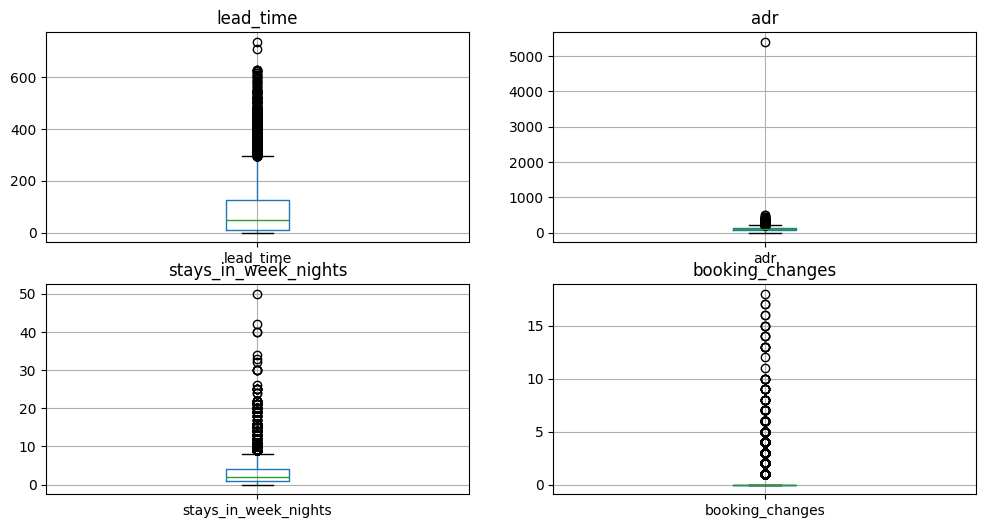

In [26]:
cols = ['lead_time', 'adr', 'stays_in_week_nights', 'booking_changes']
plt.figure(figsize=(12,6))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df.boxplot(column=col)
  plt.title(col)
plt.show()

In [27]:
Q1 = df['adr'].quantile(0.25)
Q3 = df['adr'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = max(Q1 - 1.5 * IQR, 0)
upper_bound = Q3 + 1.5 * IQR
n = ((df['adr'] < lower_bound) | (df['adr'] > upper_bound)).sum()
df['adr'] = df['adr'].clip(lower_bound, upper_bound)
cleaning.append(['Outliers en adr (max 5.400)', 'adr de -6,38 a 5.400', 'Recortar con IQR', n, len(df)])
print(lower_bound, upper_bound, n)

0 226.875 2508


In [28]:
n = (df['adr'] == 0).sum()
cleaning.append(['adr = 0', '1.959', 'Conservar (cortesias)', 0, len(df)])
print(n)

1631


- `adr` tenía un máximo de 5.400 cuando la mediana es cercana a 100. Se recortan con IQR 2.508 valores (límites 0 y 226,9). Se recorta en vez de borrar para no perder reservas.
- El IQR solo se aplica a `adr`. En variables como `adults` casi todos los valores son 2, el IQR es 0 y cualquier otro valor saldría como outlier sin serlo.
- Las 1.631 reservas con `adr = 0` se conservan porque pueden ser cortesías.

### 3.7 Resumen de la limpieza

In [29]:
cleaning = pd.DataFrame(cleaning, columns=['Problema', 'Conteo 1er corte', 'Tratamiento', 'Filas afectadas', 'Filas despues'])
cleaning

,Problema,Conteo 1er corte,Tratamiento,Filas afectadas,Filas despues
0,meal = Undefined,1.169,Reemplazar por SC,1169,119390
1,market_segment o distribution_channel = Undefined,Mencionado,Eliminar filas,5,119385
2,Reservas con 0 huespedes,180,Eliminar filas,180,119205
3,adr negativo,1,Eliminar filas,1,119204
4,"adults, children o babies imposibles",adults = 55,Eliminar filas,15,119189
5,company con nulos,112.593,Eliminar la columna,112421,119189
6,agent con nulos,16.340,Imputar como None (sin agente),16270,119189
7,country con nulos,488,Imputar como Unknown,478,119189
8,children con nulos,4,Imputar con 0,0,119189
9,Tipos incorrectos: children (float) y agent (n...,No reportado,"children a entero, agent a texto",0,119189


In [30]:
print('Filas iniciales:', rows_start)
print('Filas finales:', len(df))
print('Filas eliminadas:', rows_start - len(df))
print('Columnas finales:', df.shape[1])

Filas iniciales: 119390
Filas finales: 87202
Filas eliminadas: 32188
Columnas finales: 28


In [31]:
df['is_canceled'].value_counts(normalize=True)

is_canceled
0    0.724869
1    0.275131
Name: proportion, dtype: float64

Quedan **87.202 filas y 28 columnas** (se eliminaron 32.188 filas, el 27%, casi todas duplicadas). El balance de clases cambia de 63% / 37% a **72,5% / 27,5%**, porque muchas de las filas duplicadas eran cancelaciones.

## 4. Análisis exploratorio de datos

### 4.1 Univariado

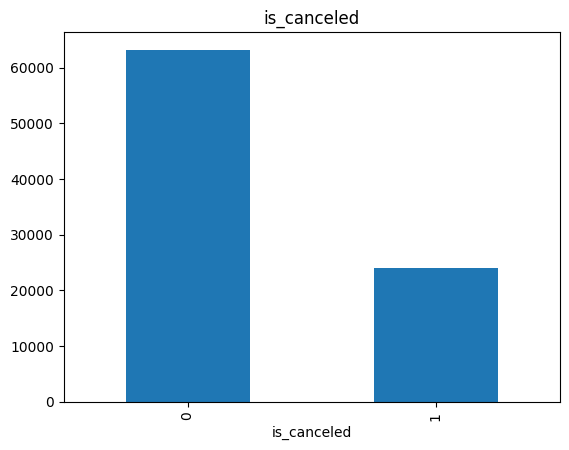

In [32]:
df['is_canceled'].value_counts().plot(kind='bar')
plt.title('is_canceled')
plt.show()

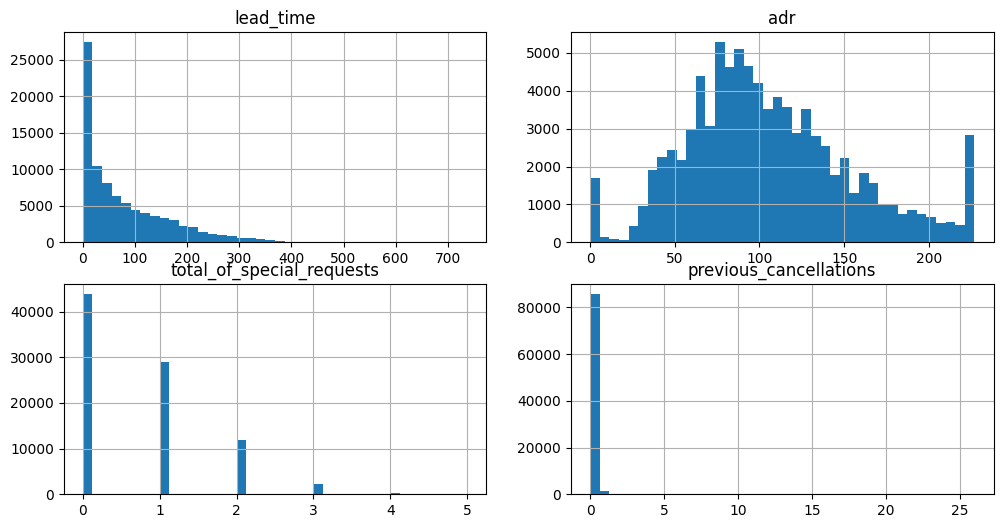

In [33]:
cols = ['lead_time', 'adr', 'total_of_special_requests', 'previous_cancellations']
plt.figure(figsize=(12,6))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df[col].hist(bins=40)
  plt.title(col)
plt.show()

In [34]:
df[['lead_time', 'adr', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list']].skew()

lead_time                          1.430660
adr                                0.515094
previous_cancellations            34.324174
previous_bookings_not_canceled    20.452890
booking_changes                    5.069508
days_in_waiting_list              19.464110
dtype: float64

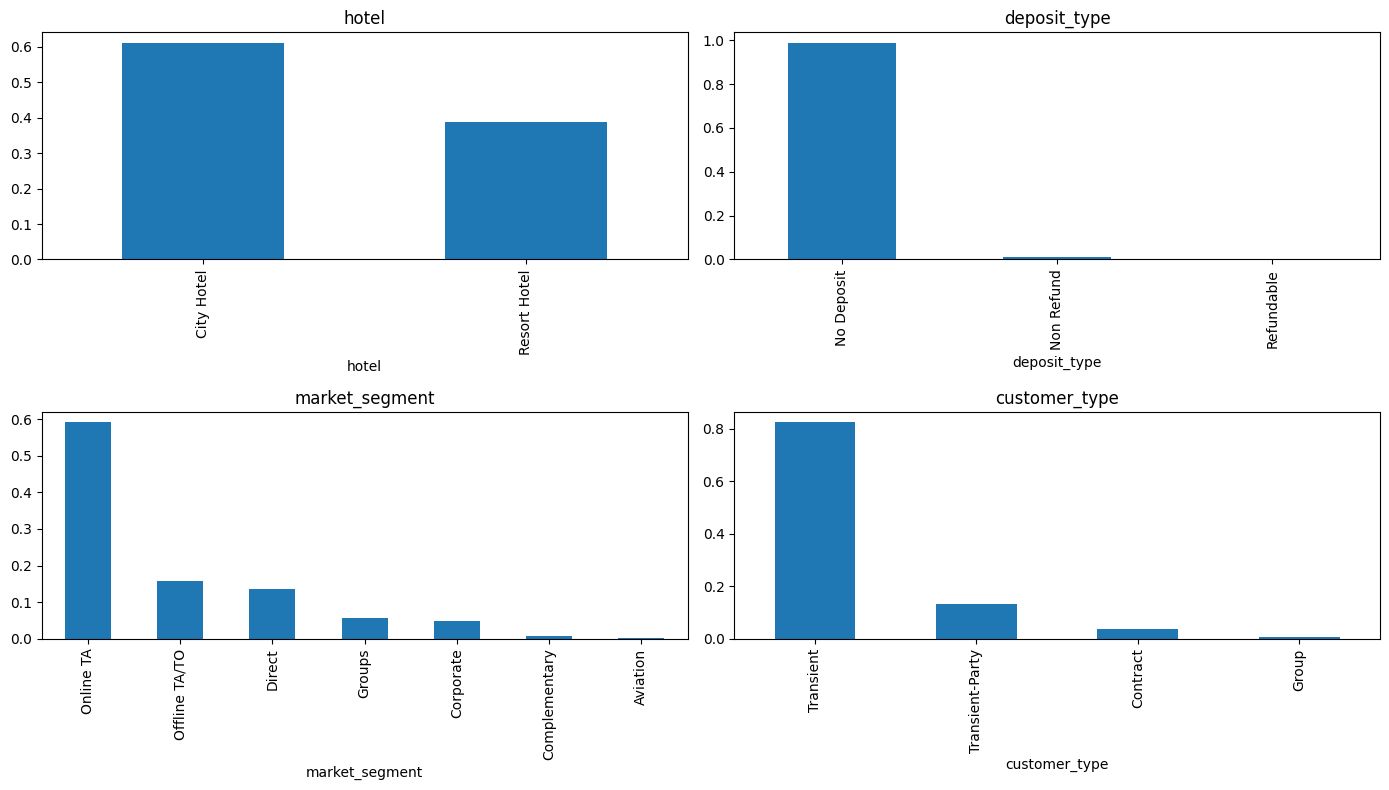

In [35]:
cols = ['hotel', 'deposit_type', 'market_segment', 'customer_type']
plt.figure(figsize=(14,8))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df[col].value_counts(normalize=True).plot(kind='bar')
  plt.title(col)
plt.tight_layout()
plt.show()

In [36]:
print('country:', df['country'].nunique())
print('agent:', df['agent'].nunique())

country: 178
agent: 334


**Hallazgos univariados**
- El 72,5% de las reservas se mantiene y el 27,5% se cancela. Un modelo que diga siempre "se mantiene" tendría 72,5% de accuracy y no detectaría ninguna cancelación, por eso la métrica principal es F1 y Recall.
- `lead_time` tiene cola larga a la derecha (mediana 49 días, máximo 737) y las variables de conteo como `previous_cancellations` están dominadas por ceros. Esto justifica aplicar logaritmo antes de escalar.
- El 61% de las reservas es del hotel de ciudad, el 98,7% no tiene depósito, el 59% viene de agencias en línea y el 82% son clientes `Transient`.
- `country` tiene 178 categorías y `agent` 334. Portugal concentra el 31% de las reservas. Esto justifica agrupar en top 10 + Other.

### 4.2 Bivariado

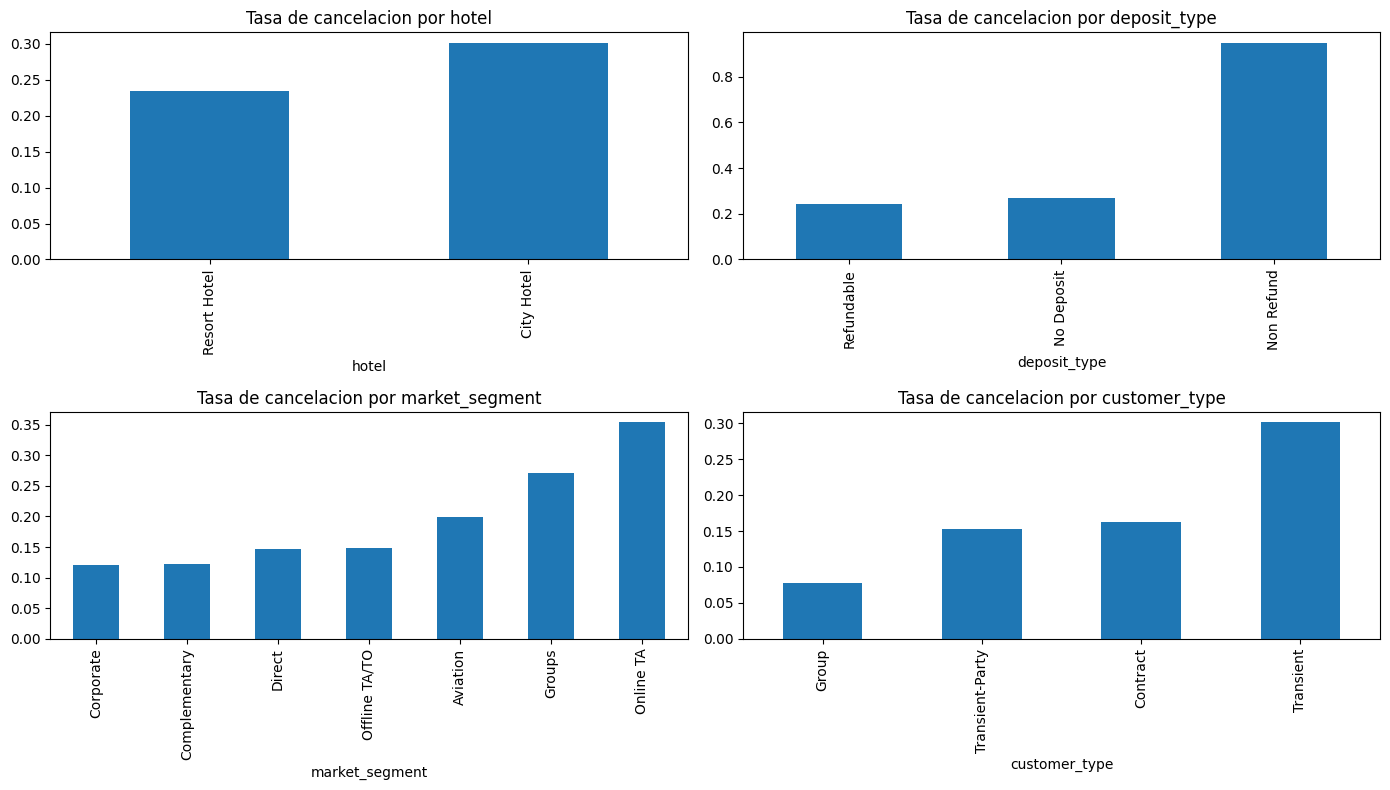

In [37]:
cols = ['hotel', 'deposit_type', 'market_segment', 'customer_type']
plt.figure(figsize=(14,8))
for col in cols:
  plt.subplot(2,2,cols.index(col)+1)
  df.groupby(col)['is_canceled'].mean().sort_values().plot(kind='bar')
  plt.title('Tasa de cancelacion por ' + col)
plt.tight_layout()
plt.show()

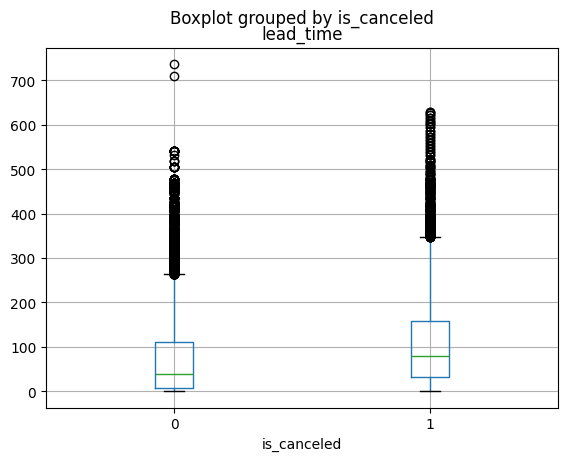

In [38]:
df.boxplot(column='lead_time', by='is_canceled')
plt.show()

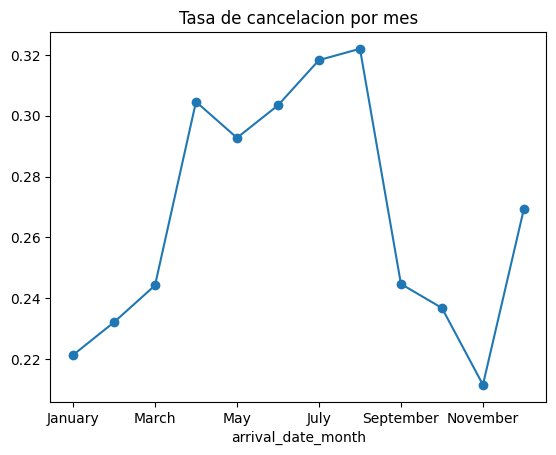

In [39]:
months = ['January','February','March','April','May','June','July','August','September','October','November','December']
df.groupby('arrival_date_month')['is_canceled'].mean().reindex(months).plot(marker='o')
plt.title('Tasa de cancelacion por mes')
plt.show()

In [40]:
comparison = pd.DataFrame([
  ['Hotel: ciudad vs resort', '41,7% vs 27,8%', df[df['hotel'] == 'City Hotel']['is_canceled'].mean(), df[df['hotel'] == 'Resort Hotel']['is_canceled'].mean()],
  ['Deposito: Non Refund vs No Deposit', '99,4% vs 28,4%', df[df['deposit_type'] == 'Non Refund']['is_canceled'].mean(), df[df['deposit_type'] == 'No Deposit']['is_canceled'].mean()],
  ['Segmento: Groups vs Direct', '61,1% vs 15,3%', df[df['market_segment'] == 'Groups']['is_canceled'].mean(), df[df['market_segment'] == 'Direct']['is_canceled'].mean()],
  ['lead_time promedio: canceladas vs no', '144,8 vs 80,0', df[df['is_canceled'] == 1]['lead_time'].mean(), df[df['is_canceled'] == 0]['lead_time'].mean()],
], columns=['Comparacion', '1er corte', 'Ahora (grupo 1)', 'Ahora (grupo 2)'])
comparison.round(3)

,Comparacion,1er corte,Ahora (grupo 1),Ahora (grupo 2)
0,Hotel: ciudad vs resort,"41,7% vs 27,8%",0.301,0.235
1,Deposito: Non Refund vs No Deposit,"99,4% vs 28,4%",0.947,0.267
2,Segmento: Groups vs Direct,"61,1% vs 15,3%",0.271,0.147
3,lead_time promedio: canceladas vs no,"144,8 vs 80,0",105.641,70.192


**Hallazgos bivariados**
- **Depósito:** `Non Refund` cancela el 94,7% frente a 26,7% de `No Deposit`, pero solo aplica al 1,2% de las reservas.
- **Hotel:** el de ciudad cancela 30,1% y el resort 23,5%.
- **Segmento:** Online TA cancela 35,4%, Groups 27,1% y Direct 14,7%. Los clientes `Transient` cancelan 30,1% y los `Group` 7,8%.
- **Antelación:** la cancelación sube con el `lead_time`, de 8,4% cuando se reserva con 0 a 7 días a 40,8% con más de un año. Las canceladas tienen en promedio 105,6 días de antelación contra 70,2 de las que se mantienen.
- **Mes:** se cancela más en verano (agosto 32,2%, julio 31,8%) y menos en noviembre (21,2%) y enero (22,1%), por eso el mes de llegada entra como variable.
- **Comparación con el primer corte:** todas las diferencias se mantienen pero son menores. Los duplicados inflaban los números: Groups bajo de 61,1% a 27,1% y la diferencia entre hoteles de 41,7/27,8 a 30,1/23,5.

### 4.3 Multivariado

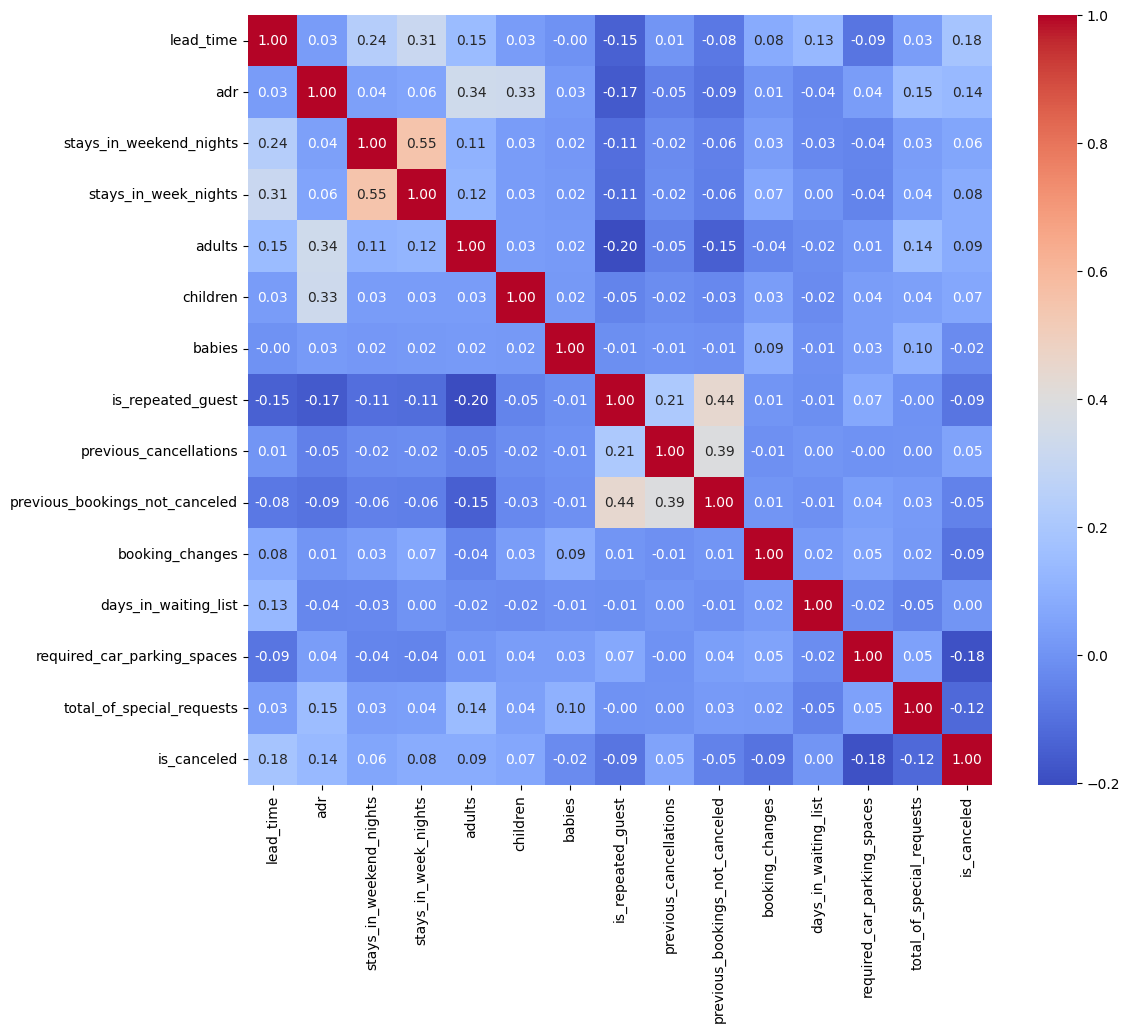

In [41]:
num_cols = ['lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
            'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes',
            'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests', 'is_canceled']
plt.figure(figsize=(12,10))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [42]:
corr = pd.DataFrame({
  '1er corte': [0.29, 0.11, -0.14, -0.20, -0.24],
  'Ahora': df[['lead_time', 'previous_cancellations', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests']].corrwith(df['is_canceled']).values
}, index=['lead_time', 'previous_cancellations', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests'])
corr.round(2)

,1er corte,Ahora
lead_time,0.29,0.18
previous_cancellations,0.11,0.05
booking_changes,-0.14,-0.09
required_car_parking_spaces,-0.20,-0.18
total_of_special_requests,-0.24,-0.12


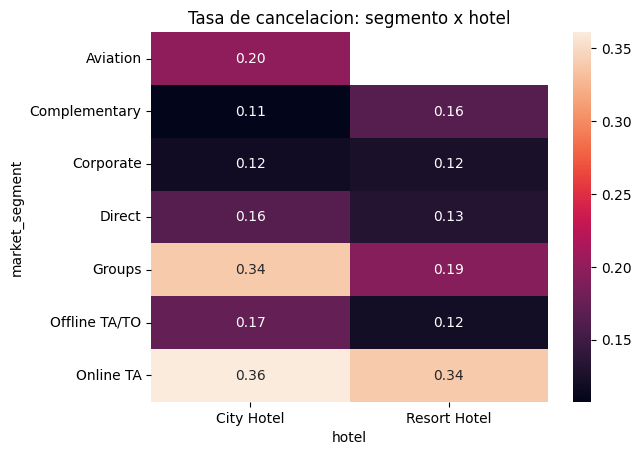

In [43]:
sns.heatmap(df.pivot_table(index='market_segment', columns='hotel', values='is_canceled', aggfunc='mean'), annot=True, fmt='.2f')
plt.title('Tasa de cancelacion: segmento x hotel')
plt.show()

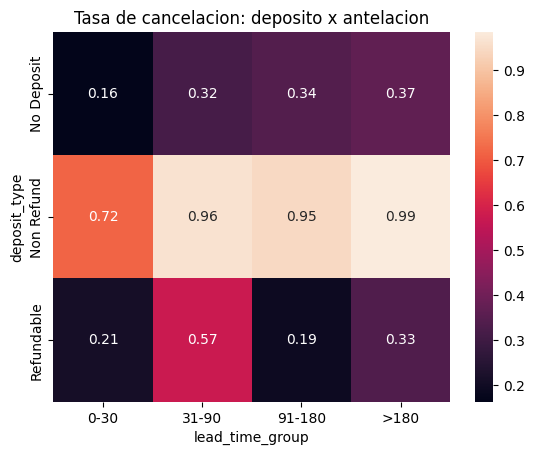

In [44]:
df['lead_time_group'] = pd.cut(df['lead_time'], bins=[-1, 30, 90, 180, 800], labels=['0-30', '31-90', '91-180', '>180'])
table = df.pivot_table(index='deposit_type', columns='lead_time_group', values='is_canceled', aggfunc='mean', observed=True)
df = df.drop(columns=['lead_time_group'])
sns.heatmap(table, annot=True, fmt='.2f')
plt.title('Tasa de cancelacion: deposito x antelacion')
plt.show()

**Hallazgos multivariados**
- **Correlaciones con el target:** son bajas y más bajas que en el primer corte (sin duplicados). `lead_time` (+0,18) y `adr` (+0,14) aumentan el riesgo; `required_car_parking_spaces` (-0,18) y `total_of_special_requests` (-0,12) lo reducen.
- **Poca colinealidad:** la correlación más alta entre variables es 0,55 (noches de semana con noches de fin de semana). No hace falta eliminar variables por colinealidad.
- **Segmento x hotel:** Groups cancela 33,9% en el hotel de ciudad pero 19,3% en el resort. El efecto de una variable depende de otra, algo que un modelo lineal no captura bien.
- **Depósito x antelación:** dentro de `No Deposit` la cancelación sube de 16,3% (0-30 días) a 36,8% (más de 180 días), y en `Non Refund` de 71,7% a 98,5%.

**Cómo apoyan la selección de variables y modelos**
- Se conservan las variables que mostraron diferencias en la tasa de cancelación: `lead_time`, `deposit_type`, `market_segment`, `hotel`, `country`, `agent`, `adr`, solicitudes especiales, parqueadero y cambios, además del mes.
- Cómo las relaciones lineales son débiles y hay interacciones (segmento x hotel), se comparan un modelo lineal (Logistic Regression) con modelos de árboles (Decision Tree y Random Forest), como se propuso en el primer corte.

## 5. Ingeniería de variables
Primero se crean variables nuevas a partir de la fecha y de las cantidades. Las columnas de año, mes, semana y día se retiran; el año no se usa porque solo tiene tres valores y no sirve para reservas futuras.

In [45]:
months = {'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,'July':7,'August':8,'September':9,'October':10,'November':11,'December':12}
df['arrival_month'] = df['arrival_date_month'].map(months)
date = pd.to_datetime(pd.DataFrame({'year': df['arrival_date_year'], 'month': df['arrival_month'], 'day': df['arrival_date_day_of_month']}))
df['arrival_dow'] = date.dt.dayofweek
df['arrival_weekend'] = (df['arrival_dow'] >= 5).astype(int)

In [46]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['has_children'] = ((df['children'] + df['babies']) > 0).astype(int)

In [47]:
df = df.drop(columns=['arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month'])
df[['arrival_month', 'arrival_dow', 'arrival_weekend', 'total_nights', 'total_guests', 'has_children']].head()

,arrival_month,arrival_dow,arrival_weekend,total_nights,total_guests,has_children
0,7,2,0,0,2,0
1,7,2,0,0,2,0
2,7,2,0,1,1,0
3,7,2,0,1,1,0
4,7,2,0,2,2,0


Agrupacion de las categorías de alta cardinalidad en las 10 más frecuentes y `Other`:

In [48]:
top_country = df['country'].value_counts().head(10).index.tolist()
top_agent = df['agent'].value_counts().head(10).index.tolist()
df['country'] = df['country'].where(df['country'].isin(top_country), 'Other')
df['agent'] = df['agent'].where(df['agent'].isin(top_agent), 'Other')
print(df['country'].value_counts())
print(df['agent'].value_counts())

country
PRT      27332
Other    15937
GBR      10421
FRA       8823
ESP       7244
DEU       5385
ITA       3061
IRL       3015
BEL       2081
BRA       1993
NLD       1910
Name: count, dtype: int64
agent
9        28717
Other    18170
240      13027
None     12127
14        3341
7         3294
250       2779
241       1644
28        1493
8         1382
1         1228
Name: count, dtype: int64


Logaritmo en las variables con cola larga (`adr` no, porque después del recorte por IQR ya queda casi simétrica):

In [49]:
log_cols = ['lead_time', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list']
for col in log_cols:
  df[col] = np.log1p(df[col])
df[log_cols].skew()

lead_time                         -0.717403
previous_cancellations            10.409114
previous_bookings_not_canceled     6.982217
booking_changes                    2.251094
days_in_waiting_list              10.703942
dtype: float64

Listas de variables y one-hot de las categóricas:

In [50]:
numerical = ['lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
             'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list',
             'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_guests']
binary = ['is_repeated_guest', 'arrival_weekend', 'has_children']
categorical = ['hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type',
               'deposit_type', 'agent', 'customer_type', 'arrival_month', 'arrival_dow']
print(len(numerical) + len(binary) + len(categorical))

29


In [51]:
df[['arrival_month', 'arrival_dow']] = df[['arrival_month', 'arrival_dow']].astype(str)
data = pd.get_dummies(df[numerical + binary + categorical], columns=categorical, dtype=int)
data.shape

(87202, 92)

División 80/20 estratificada y escalado. El `StandardScaler` se ajusta solo con train y después se aplica a test, para no filtrar información del conjunto de prueba.

In [52]:
from sklearn.model_selection import train_test_split
X = data
y = df['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(69761, 92) (17441, 92)
0.2751250698814524 0.2751562410412247


In [53]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[numerical] = scaler.fit_transform(X_train[numerical])
X_test[numerical] = scaler.transform(X_test[numerical])
X_train[numerical].describe().loc[['mean', 'std']].round(2)

,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,total_nights,total_guests
mean,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Quedan 29 variables de entrada que se convierten en 92 columnas: 15 numéricas escaladas, 3 binarias y 74 columnas del one-hot. Train tiene 69.761 filas y test 17.441, los dos con 27,5% de cancelaciones.

## 6. Reducción de dimensionalidad
**Por qué.** Después del one-hot hay 92 columnas, muchas de ellas con casi todo en cero. Se prueba si reducirlas mantiene el desempeño con menos columnas. Se usan las dos técnicas vistas en clase: PCA (no supervisada, busca las direcciones de mayor varianza) y LDA (supervisada, busca la dirección que mejor separa las clases). Las dos se ajustan solo con train.

### 6.1 PCA

In [54]:
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(X_train)
variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(variance >= 0.95) + 1
print('Componentes para el 95%:', n_components, 'de', X_train.shape[1])
print('Varianza explicada:', variance[n_components - 1])

Componentes para el 95%: 39 de 92
Varianza explicada: 0.9518732392572735


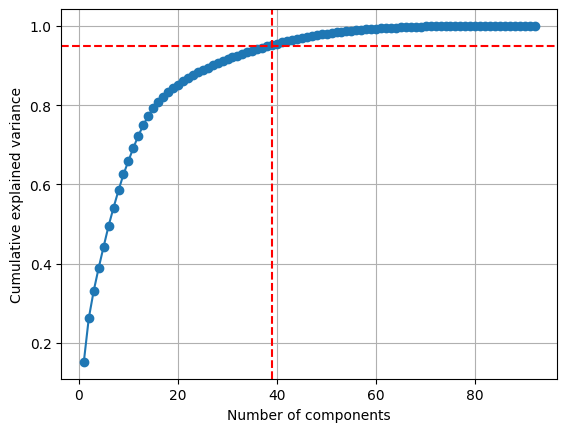

In [55]:
plt.plot(range(1, len(variance) + 1), variance, marker='o')
plt.axhline(0.95, color='red', linestyle='--')
plt.axvline(n_components, color='red', linestyle='--')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid()
plt.show()

In [56]:
pca = PCA(n_components=n_components)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(X_train_pca.shape, pca.explained_variance_ratio_.sum())

(69761, 39) 0.9518732392572735


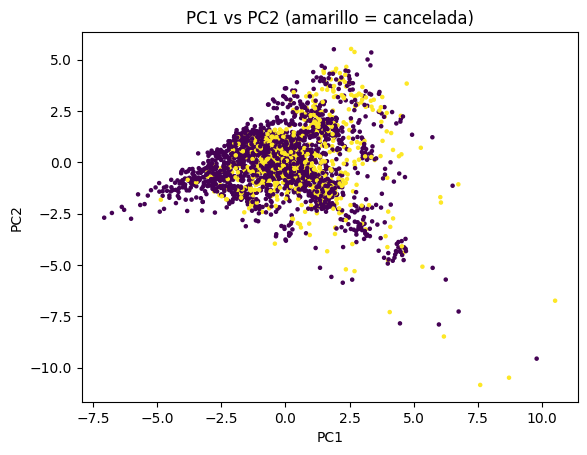

In [57]:
plt.scatter(X_train_pca[:3000, 0], X_train_pca[:3000, 1], c=y_train[:3000], s=5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC1 vs PC2 (amarillo = cancelada)')
plt.show()

Se necesitan **39 componentes de 92 para conservar el 95,2% de la varianza**. En el plano PC1 vs PC2 las reservas canceladas y no canceladas se mezclan: PCA busca la mayor varianza, no lo que separa las clases.

### 6.2 LDA

In [58]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)
print(X_train_lda.shape)

(69761, 1)


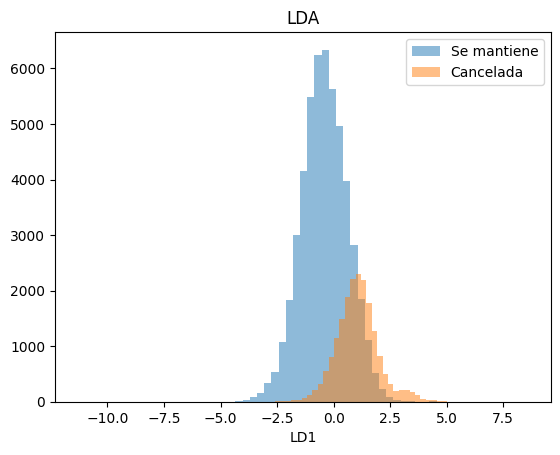

In [59]:
plt.hist(X_train_lda[y_train == 0], bins=50, alpha=0.5, label='Se mantiene')
plt.hist(X_train_lda[y_train == 1], bins=50, alpha=0.5, label='Cancelada')
plt.xlabel('LD1')
plt.legend()
plt.title('LDA')
plt.show()

Con dos clases, LDA solo puede dar **1 componente** (clases - 1). Las dos distribuciones se separan en parte pero se solapan bastante. El efecto de PCA y LDA sobre los modelos se mide en la sección 7.

## 7. Modelado
**Modelos (los del primer corte):**
- **Logistic Regression:** modelo lineal base e interpretable.
- **Decision Tree:** modelo no lineal basado en reglas, fácil de leer pero tiende al sobreajuste.
- **Random Forest:** muchos árboles que votan, reduce el sobreajuste de un árbol solo y captura interacciones.

**Entrenamiento:** validación cruzada estratificada de 5 pliegues sobre train con `GridSearchCV` para elegir hiperparámetros, usando F1 como criterio. El test solo se usa al final.

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [61]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Antes de entrenar se revisa si conviene usar pesos de clase por el desbalance (72,5% / 27,5%):

In [62]:
for weight in [None, 'balanced']:
  scores = cross_validate(LogisticRegression(max_iter=1000, class_weight=weight), X_train, y_train, cv=cv, scoring=['precision', 'recall', 'f1'])
  print(weight, 'Precision', scores['test_precision'].mean().round(3), 'Recall', scores['test_recall'].mean().round(3), 'F1', scores['test_f1'].mean().round(3))

None Precision 0.695 Recall 0.548 F1 0.613


balanced Precision 0.56 Recall 0.823 F1 0.667


Con `class_weight="balanced"` el Recall sube de 0,55 a 0,82 y el F1 de 0,61 a 0,67, a cambio de menor Precision. Para el hotel es peor no detectar una cancelación que una falsa alarma, así que se usan pesos balanceados en los tres modelos.

Cada modelo se entrena con los tres conjuntos de datos (sin reducción, PCA y LDA). Esta celda tarda unos 15 a 20 minutos.

In [63]:
models = {
  'Logistic Regression': (LogisticRegression(max_iter=1000, class_weight='balanced'), {'C': [0.1, 1, 10]}),
  'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=42), {'max_depth': [8, 14, 20], 'min_samples_leaf': [5, 20]}),
  'Random Forest': (RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1), {'max_depth': [20, None], 'min_samples_leaf': [2, 5]})
}
datasets = {
  'Sin reduccion': (X_train, X_test),
  'PCA': (X_train_pca, X_test_pca),
  'LDA': (X_train_lda, X_test_lda)
}

In [64]:
results = []
trained = {}

for data_name, (Xtr, Xte) in datasets.items():
  for model_name, (model, grid) in models.items():
    search = GridSearchCV(model, grid, cv=cv, scoring='f1', n_jobs=-1)
    search.fit(Xtr, y_train)
    best = search.best_estimator_
    y_pred = best.predict(Xte)
    y_prob = best.predict_proba(Xte)[:, 1]
    trained[(model_name, data_name)] = (best, y_pred)
    results.append([model_name, data_name, search.best_params_, search.best_score_,
                    f1_score(y_train, best.predict(Xtr)), accuracy_score(y_test, y_pred),
                    precision_score(y_test, y_pred), recall_score(y_test, y_pred),
                    f1_score(y_test, y_pred), roc_auc_score(y_test, y_prob)])
    print(model_name, '-', data_name, 'listo')

Logistic Regression - Sin reduccion listo


Decision Tree - Sin reduccion listo


Random Forest - Sin reduccion listo


Logistic Regression - PCA listo


Decision Tree - PCA listo


Random Forest - PCA listo


Logistic Regression - LDA listo


Decision Tree - LDA listo


Random Forest - LDA listo


In [65]:
results = pd.DataFrame(results, columns=['Modelo', 'Reduccion', 'Hiperparametros', 'F1 CV', 'F1 train', 'Accuracy',
                                        'Precision', 'Recall', 'F1 test', 'ROC-AUC'])
results.round(3)

,Modelo,Reduccion,Hiperparametros,F1 CV,F1 train,Accuracy,Precision,Recall,F1 test,ROC-AUC
0,Logistic Regression,Sin reduccion,{'C': 1},0.667,0.667,0.773,0.559,0.819,0.665,0.867
1,Decision Tree,Sin reduccion,"{'max_depth': 14, 'min_samples_leaf': 20}",0.675,0.698,0.780,0.567,0.850,0.680,0.883
2,Random Forest,Sin reduccion,"{'max_depth': None, 'min_samples_leaf': 2}",0.712,0.890,0.842,0.692,0.765,0.727,0.908
3,Logistic Regression,PCA,{'C': 1},0.642,0.642,0.756,0.538,0.798,0.643,0.850
4,Decision Tree,PCA,"{'max_depth': 14, 'min_samples_leaf': 20}",0.615,0.708,0.746,0.526,0.769,0.624,0.824
5,Random Forest,PCA,"{'max_depth': 20, 'min_samples_leaf': 5}",0.679,0.900,0.828,0.683,0.696,0.690,0.888
6,Logistic Regression,LDA,{'C': 1},0.663,0.663,0.775,0.565,0.792,0.659,0.860
7,Decision Tree,LDA,"{'max_depth': 8, 'min_samples_leaf': 20}",0.659,0.665,0.772,0.560,0.794,0.657,0.856
8,Random Forest,LDA,"{'max_depth': 20, 'min_samples_leaf': 5}",0.648,0.709,0.769,0.558,0.765,0.645,0.846


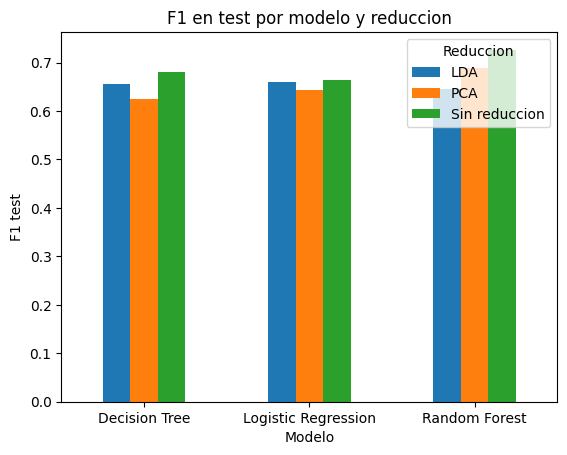

In [66]:
results.pivot_table(index='Modelo', columns='Reduccion', values='F1 test').plot(kind='bar')
plt.ylabel('F1 test')
plt.title('F1 en test por modelo y reduccion')
plt.xticks(rotation=0)
plt.show()

## 8. Evaluación y resultados

### 8.1 Sobreajuste y subajuste

In [67]:
results['Brecha train - test'] = results['F1 train'] - results['F1 test']
results[['Modelo', 'Reduccion', 'F1 train', 'F1 CV', 'F1 test', 'Brecha train - test']].round(3)

,Modelo,Reduccion,F1 train,F1 CV,F1 test,Brecha train - test
0,Logistic Regression,Sin reduccion,0.667,0.667,0.665,0.003
1,Decision Tree,Sin reduccion,0.698,0.675,0.680,0.018
2,Random Forest,Sin reduccion,0.890,0.712,0.727,0.164
3,Logistic Regression,PCA,0.642,0.642,0.643,-0.000
4,Decision Tree,PCA,0.708,0.615,0.624,0.083
5,Random Forest,PCA,0.900,0.679,0.690,0.210
6,Logistic Regression,LDA,0.663,0.663,0.659,0.003
7,Decision Tree,LDA,0.665,0.659,0.657,0.008
8,Random Forest,LDA,0.709,0.648,0.645,0.064


- **Logistic Regression:** casi el mismo F1 en train (0,667) y test (0,665). No hay sobreajuste, pero su F1 es menor que el de los árboles: el modelo lineal se queda corto para estas relaciones (subajuste leve).
- **Decision Tree:** brecha pequeña (0,698 en train y 0,680 en test).
- **Random Forest:** F1 de 0,890 en train y 0,727 en test, una brecha de 0,16. Memoriza parte de los datos de entrenamiento, algo normal en bosques con árboles profundos. Aún así el F1 de validación cruzada (0,712) y el de test (0,727) son casi iguales, así que generaliza bien a datos nuevos.

### 8.2 Matrices de confusión (sin reducción)

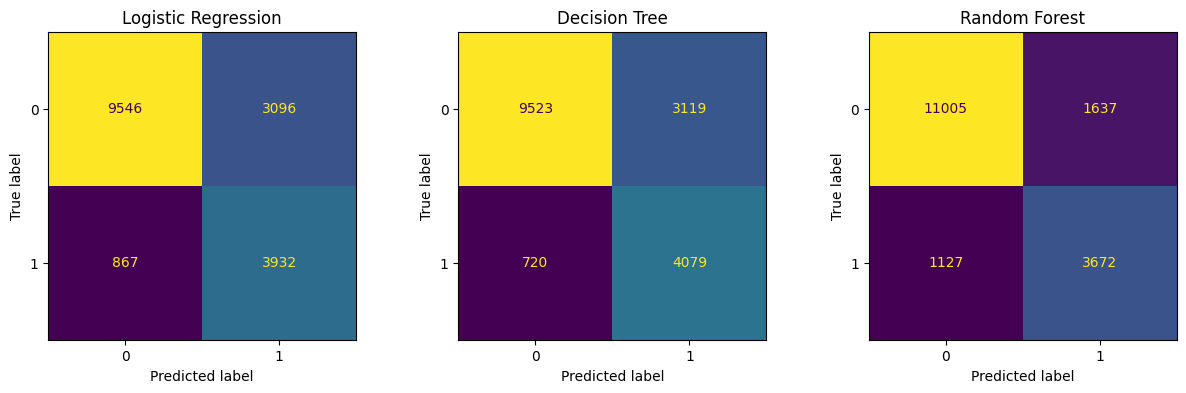

In [68]:
plt.figure(figsize=(15,4))
for model_name in models:
  ax = plt.subplot(1,3,list(models).index(model_name)+1)
  ConfusionMatrixDisplay.from_predictions(y_test, trained[(model_name, 'Sin reduccion')][1], ax=ax, colorbar=False)
  ax.set_title(model_name)
plt.show()

### 8.3 Mejor modelo

In [69]:
best_row = results.sort_values(by='F1 CV', ascending=False).iloc[0]
best_row

Modelo                                              Random Forest
Reduccion                                           Sin reduccion
Hiperparametros        {'max_depth': None, 'min_samples_leaf': 2}
F1 CV                                                     0.71219
F1 train                                                 0.890329
Accuracy                                                 0.841523
Precision                                                0.691656
Recall                                                   0.765159
F1 test                                                  0.726553
ROC-AUC                                                  0.908407
Brecha train - test                                      0.163776
Name: 2, dtype: object

In [70]:
best_model, best_pred = trained[(best_row['Modelo'], best_row['Reduccion'])]
print(classification_report(y_test, best_pred, target_names=['Se mantiene', 'Cancelada']))
print(confusion_matrix(y_test, best_pred))

              precision    recall  f1-score   support

 Se mantiene       0.91      0.87      0.89     12642
   Cancelada       0.69      0.77      0.73      4799

    accuracy                           0.84     17441
   macro avg       0.80      0.82      0.81     17441
weighted avg       0.85      0.84      0.84     17441

[[11005  1637]
 [ 1127  3672]]


In [71]:
print('Predecir siempre "se mantiene": accuracy', (y_test == 0).mean().round(3), 'y recall 0')

Predecir siempre "se mantiene": accuracy 0.725 y recall 0


**Mejor modelo: Random Forest sin reducción** (`max_depth=None`, `min_samples_leaf=2`), elegido por tener el mayor F1 en validación cruzada (0,712).

En test: accuracy 0,842, Precision 0,692, Recall 0,765, F1 0,727 y ROC-AUC 0,908. Detecta 3.672 de las 4.799 cancelaciones reales (77%), y de las 5.309 reservas que marca como canceladas, 3.672 lo son (69%). Comparado con predecir siempre "se mantiene" (accuracy 0,725 y Recall 0), mejora en todo.

El Decision Tree tiene un Recall más alto (0,850) pero mucho menor Precision (0,567), es decir, más falsas alarmas. Por eso se eligió por F1, que equilibra los dos errores.

### 8.4 Impacto de la reducción de dimensionalidad

In [72]:
results.pivot_table(index='Modelo', columns='Reduccion', values=['F1 test', 'ROC-AUC']).round(3)

F1 test                      ROC-AUC                     
Reduccion               LDA    PCA Sin reduccion     LDA    PCA Sin reduccion
Modelo                                                                       
Decision Tree         0.657  0.624         0.680   0.856  0.824         0.883
Logistic Regression   0.659  0.643         0.665   0.860  0.850         0.867
Random Forest         0.645  0.690         0.727   0.846  0.888         0.908

- **PCA (92 a 39 columnas) empeora los tres modelos:** el F1 baja de 0,665 a 0,643 en Logistic Regression, de 0,680 a 0,624 en Decision Tree y de 0,727 a 0,690 en Random Forest. El 5% de varianza que se descarta tiene información útil (por ejemplo depósito, país o agente, que tienen poca varianza pero mucha relación con la cancelación).
- **LDA (92 a 1 columna)** casi no afecta a Logistic Regression (0,665 a 0,659) porque los dos son lineales, pero baja mucho el Random Forest (0,727 a 0,645), que con una sola columna ya no puede combinar variables.
- **Conclusión:** la reducción no mejora el desempeño en este problema, 92 columnas no son demasiadas para entrenar, y el modelo final se entrena sin reducción. PCA y LDA sirvieron para ver que la información no se concentra en pocas direcciones.

### 8.5 Variables más importantes

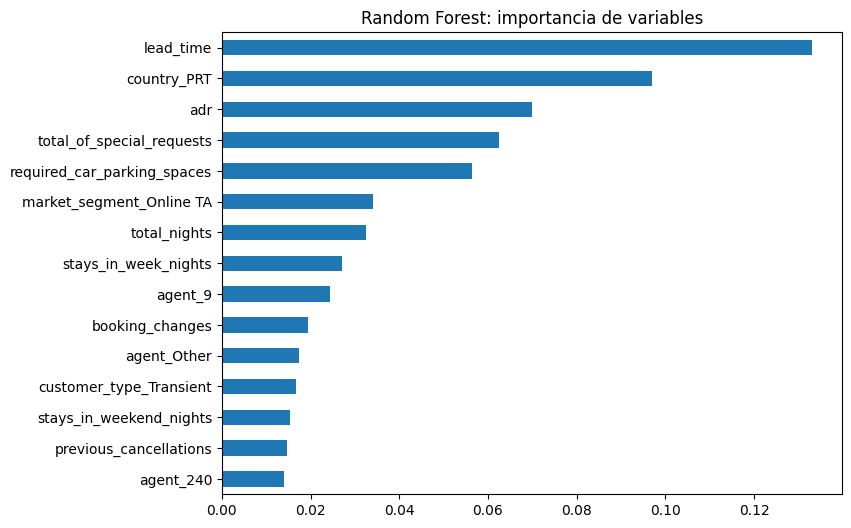

In [73]:
rf = trained[('Random Forest', 'Sin reduccion')][0]
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
importance.sort_values().plot(kind='barh', figsize=(8,6))
plt.title('Random Forest: importancia de variables')
plt.show()

Las variables que más usa el Random Forest son `lead_time`, reservar desde Portugal, la tarifa (`adr`), las solicitudes especiales y el parqueadero. Coincide con el EDA: las reservas con mucha antelación, de agencias en línea y sin solicitudes especiales son las de más riesgo.

### 8.6 Conclusiones
- **Respuesta al problema:** si es posible anticipar que reservas se van a cancelar. El Random Forest detecta unas 77 de cada 100 cancelaciones y 69 de cada 100 alertas son cancelaciones reales.
- **Uso en el hotel:** sirve para acciones de bajo costo ante una falsa alarma, como pedir confirmación al cliente o ajustar el overbooking. No conviene para rechazar huéspedes automáticamente, porque 3 de cada 10 alertas son falsas.
- El modelo de árboles supera al lineal, como anticipaban las interacciones del EDA, y la reducción de dimensionalidad no aportó mejoras.

### 8.7 Limitaciones y mejoras
- **Variables posteriores a la reserva:** parqueadero, solicitudes especiales y cambios se pueden registrar después de reservar. Se usaron porque estaban en el plan del primer corte, pero el desempeño en el instante exacto de reservar sería algo menor.
- **Validación aleatoria:** los datos son de 2015 a 2017 y de dos hoteles de Portugal; en otros años u hoteles el desempeño puede cambiar. Una mejora sería validar por fechas.
- **Duplicados:** el dataset no tiene un ID de reserva, así que algunas filas iguales podrían ser reservas distintas (por ejemplo varias habitaciones de un mismo grupo).
- **Categorías raras:** `Non Refund` (1.038 filas) y `Refundable` (107) tienen pocos casos.
- **Sobreajuste del Random Forest:** la brecha entre train y test es de 0,16. Se podría limitar la profundidad o probar más hiperparámetros.
- **Umbral fijo de 0,5:** se podría ajustar según el costo real de una falsa alarma frente a una cancelación no detectada.

## 9. Guardar el modelo para la aplicación
Se guarda en `models/modelo.joblib` el mejor modelo junto con todo lo que necesita para transformar una reserva nueva igual que en el entrenamiento: el `StandardScaler` ajustado, las columnas del one-hot, las listas de variables, los países y agentes del top 10 y los límites del IQR de `adr`. También se guarda la tabla de resultados, las importancias y una muestra de 1.000 reservas del conjunto de prueba para la demostración.

La aplicación (`app.py`) carga ese archivo y usa las funciones de `model.py`, que repiten los mismos pasos de limpieza e ingeniería de variables de este cuaderno.

In [74]:
import joblib
import os
os.makedirs('models', exist_ok=True)
os.makedirs('data', exist_ok=True)
joblib.dump({
  'model': best_model,
  'scaler': scaler,
  'columns': X_train.columns.tolist(),
  'numerical': numerical,
  'binary': binary,
  'categorical': categorical,
  'log_cols': log_cols,
  'top_country': top_country,
  'top_agent': top_agent,
  'adr_bounds': [lower_bound, upper_bound],
  'reduction': best_row['Reduccion'],
  'pca': pca,
  'lda': lda,
  'model_name': best_row['Modelo'] + ' (' + best_row['Reduccion'] + ')',
  'params': best_row['Hiperparametros'],
  'base_rate': y.mean(),
  'options': {col: sorted(df[col].unique().tolist()) for col in ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']}
}, 'models/modelo.joblib', compress=3)
results.drop(columns=['Hiperparametros']).round(3).to_csv('models/resultados.csv', index=False)
pd.DataFrame({'variable': importance.index, 'importancia': importance.values}).to_csv('models/importancias.csv', index=False)

In [75]:
raw = pd.read_csv(url)
sample = raw.loc[X_test.index[:1000]]
sample.to_csv('data/muestra_test.csv', index=False)
sample.shape

(1000, 32)